In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydhn
from pydhn.fluids import Fluid
from pydhn.soils import Soil
from pydhn.solving import SimpleStep, Scheduler

In [23]:
# ---------------------------------------------------------------------------
# Simulation parameters
# ---------------------------------------------------------------------------
STEPSIZE       = 600          # time step [s]  (10 min)
NUM_SIM_STEPS  = 1008         # 7 days × 144 steps/day
T_AMBIENT_C    = 10.0         # ambient / ground temperature [°C]

In [24]:
# ---------------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------------
PIPES_FILE = "pipes.csv"
NODES_FILE = "nodes.csv"
DEMAND_PROFILE_FILE = "../../data/demand_profile.csv"

# ---------------------------------------------------------------------------
# Load input data
# ---------------------------------------------------------------------------
pipe_data = pd.read_csv(PIPES_FILE)
node_data = pd.read_csv(NODES_FILE)
demand_profile_data = pd.read_csv(DEMAND_PROFILE_FILE)
demand_profile_data = demand_profile_data[:NUM_SIM_STEPS]

time_sim   = demand_profile_data["timestep"].values * STEPSIZE  # [s]
heat_demand = demand_profile_data["Q_W"] * (STEPSIZE / 3600)    # [Wh]
MDOT_BYPASS_KGS = 1.77 / 3600                                   # [kg/s], bypass mass flow

print(f"Loaded topological data from {PIPES_FILE} "
      f"--- dynamic simulation of {len(demand_profile_data)} time steps.")

Loaded topological data from pipes.csv --- dynamic simulation of 1008 time steps.


In [25]:
# ---------------------------------------------------------------------------
# Fluid and soil
# ---------------------------------------------------------------------------
# Properties taken from first pipe row (homogeneous network assumption)
p0 = pipe_data.iloc[0]

fluid = Fluid(
    name       = "Water",
    isconstant = True,
    cp         = p0["fluid_cp_JkgK"],
    mu         = p0["fluid_mu_Pas"],
    rho        = p0["fluid_rho_kgm3"],
    k          = p0["fluid_lambda_WmK"],
)

soil = Soil(
    k    = p0["soil_lambda_WmK"],
    temp = p0["T_ground_degC"],
)

# ---------------------------------------------------------------------------
# Built network
# ---------------------------------------------------------------------------
net = pydhn.Network()

# Add nodes
for _, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]
    X, Y      = row["x_m"], row["y_m"]

    name_s = f"{name}_s"
    name_r = f"{name}_r"

    net.add_node(name=name_s, x=X, y=-Y)
    net.add_node(name=name_r, x=X, y=-Y)

    # Add substations
    if node_type == "substation":
        delta_t = float(row["delta_T_nom_K"])
        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "mass_flow",
            setpoint_type_hyd = "mass_flow",
            setpoint_value_hyd = MDOT_BYPASS_KGS,   # kg/s, initial value
            setpoint_type_hx  = "delta_q",
            setpoint_value_hx = 0.0,                # Wh, initial value
            design_delta_t    = delta_t,
            t_out_min_hx      = 20,
            stepsize          = STEPSIZE,
        )

    # Add central generator
    elif node_type == "source":
        t_supply = float(row["T_supply_set_degC"])
        net.add_producer(
            name                = name,
            start_node          = name_r,
            end_node            = name_s,
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_supply,
            stepsize            = STEPSIZE,
        )

# Add pipes
for _, row in pipe_data.iterrows():
    name = row["pipe_id"]
    frm  = row["from_node"]
    to   = row["to_node"]

    common = dict(
        # --- geometry ---
        diameter                = row["d_inner_m"],                 # carrier pipe inner diameter [m]
        length                  = row["length_m"],                  # pipe length [m]
        internal_pipe_thickness = row["wall_m"],                    # steel wall thickness [m]
        insulation_thickness    = row["insulation_thickness_m"],    # PUR foam thickness [m]
        casing_thickness        = row["casing_thickness_m"],        # HDPE casing wall thickness [m]
        # --- hydraulic ---
        roughness               = row["roughness_mm"],              # absolute roughness [mm]
        # --- thermal: insulation ---
        k_insulation            = row["PUR_lambda_WmK"],            # PUR thermal conductivity [W/(m·K)]
        # --- thermal: carrier pipe ---
        k_internal_pipe         = row["steel_lambda_WmK"],          # steel thermal conductivity [W/(m·K)]
        rho_wall                = row["steel_rho_kgm3"],            # steel density [kg/m³]
        cp_wall                 = row["steel_cp_JkgK"],             # steel specific heat [J/(kg·K)]
        # --- thermal: casing ---
        k_casing                = row["HDPE_lambda_WmK"],           # HDPE thermal conductivity [W/(m·K)]
        # --- burial ---
        depth                   = row["burial_depth_m"],            # burial depth [m]
        h_ext                   = row["h_ext_Wm2K"],                # external heat transfer coeff. [W/(m²·K)]
        # --- simulation ---
        stepsize                = STEPSIZE,                         # time step [s]
    )

    # Supply pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_s",
        start_node = f"{frm}_s",
        end_node   = f"{to}_s",
        line       = "supply",
        **common,
    )

    # Return pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_r",
        start_node = f"{to}_r",
        end_node   = f"{frm}_r",
        line       = "return",
        **common,
    )

print("--- Network setup complete. ---")

--- Network setup complete. ---


In [26]:
# ---------------------------------------------------------------------------
# Schedules
# ---------------------------------------------------------------------------
consumer_demand_schedule   = pd.DataFrame()
consumer_massflow_schedule = pd.DataFrame()
consumer_names = []

for i in node_data.index:
    row       = node_data.loc[i]
    name      = row["node_id"]
    node_type = row["node_type"]

    if node_type == "substation":
        consumer_names.append(name)
        delta_t = float(row["delta_T_nom_K"])

        q_w  = demand_profile_data["Q_W"].values          # [W]
        q_wh = heat_demand

        mdot = np.where(
            q_w == 0,
            MDOT_BYPASS_KGS,                              # bypass [kg/s]
            q_w / (fluid.cp * delta_t)                    # nominal mass flow [kg/s]
        )

        q_schedule = np.where(q_w == 0, 0.0, -q_wh)      # [Wh]

        consumer_massflow_schedule[name] = mdot
        consumer_demand_schedule[name]   = q_schedule

consumer_massflow_schedule = consumer_massflow_schedule[consumer_names]
consumer_demand_schedule   = consumer_demand_schedule[consumer_names]

schedules = {
    "setpoint_value_hyd": consumer_massflow_schedule,   # [kg/s]
    "setpoint_value_hx":  consumer_demand_schedule,     # [Wh]
}

print(f"Schedules built: {len(consumer_names)} consumers × {NUM_SIM_STEPS} steps.")

Schedules built: 10 consumers × 1008 steps.


In [27]:
# ---------------------------------------------------------------------------
# Pre-heating (network initialization)
# ---------------------------------------------------------------------------
print("--- Initializing Network (Pre-heating for stability) ---")

INIT_STEPS = 144  # 1 day

init_demand_consumer = pd.DataFrame(
    np.tile(consumer_demand_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=consumer_demand_schedule.columns,
)

init_schedules = {
    "heat_demand": init_demand_consumer
}

base_loop_init = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler_init = Scheduler(
    base_loop=base_loop_init,
    schedules=init_schedules,
    steps=INIT_STEPS,
)

import time
t0 = time.perf_counter()
_  = scheduler_init.execute(net=net, fluid=fluid, soil=soil)
print(f"Pre-heating done in {time.perf_counter()-t0:.2f} s. "
      f"({INIT_STEPS} steps = {INIT_STEPS*STEPSIZE/3600:.1f} h.)")

--- Initializing Network (Pre-heating for stability) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started


C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\.venv\Lib\site-packages\pydhn\utilities\matrices.py:187: FutureWarning: incidence_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return nx.incidence_matrix(


Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop started
Loop completed
Step 26:
Loop started
Loop completed
Step 27:
Loop started
Loop completed
Step 28:
Loop started
Loop completed
Step 29:
Loop started
Loop completed
Step 30:
Loop started
Loop completed
Step 31:
Loop started
Loop completed
Step 32:
Loop started
Loop 

In [28]:
# ---------------------------------------------------------------------------
# Full simulation
# ---------------------------------------------------------------------------
print("--- Running with Scheduler (Full Simulation) ---")

base_loop_scheduler = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs  ={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler = Scheduler(
    base_loop=base_loop_scheduler,
    schedules=schedules,
    steps=NUM_SIM_STEPS,
)

t0 = time.perf_counter()
results = scheduler.execute(net=net, fluid=fluid, soil=soil)
sim_time = time.perf_counter() - t0

print(f"Simulation complete.")
print(f"Average simulation time: {sim_time:.2f} s.")

--- Running with Scheduler (Full Simulation) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop star

In [53]:
# ---------------------------------------------------------------------------
# Extracted variables
# ---------------------------------------------------------------------------
res = results.to_dataframes()

substation_names = node_data[node_data["node_type"] == "substation"]["node_id"].tolist()
source_name      = node_data[node_data["node_type"] == "source"]["node_id"].iloc[0]
pipe_names       = pipe_data["pipe_id"].tolist()

# ── ETS ────────────────────────────────────────────────────────────

T_sub_s  = res["nodes"]["temperature"][[f"{n}_s" for n in substation_names]]
T_sub_r  = res["nodes"]["temperature"][[f"{n}_r" for n in substation_names]]
mdot_sub = res["edges"]["mass_flow"][substation_names]

# ── PRODUCER ─────────────────────────────────────────────────────────────────
T_src_r  = res["nodes"]["temperature"][f"{source_name}_r"]
mdot_src = res["edges"]["mass_flow"][source_name]
Q_src_W  = res["edges"]["delta_q"][source_name] / (STEPSIZE / 3600)

# ── PIPE ─────────────────────────────────────────────────────────────────────
dp_pipe_s = res["edges"]["delta_p"][[f"{n}_s" for n in pipe_names]]
dp_pipe_r = res["edges"]["delta_p"][[f"{n}_r" for n in pipe_names]]
mdot_pipe_s = res["edges"]["mass_flow"][[f"{n}_s" for n in pipe_names]]
mdot_pipe_r = res["edges"]["mass_flow"][[f"{n}_r" for n in pipe_names]]
T_pipe_s = res["edges"]["temperature"][[f"{n}_s" for n in pipe_names]]
T_pipe_r = res["edges"]["temperature"][[f"{n}_r" for n in pipe_names]]

# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
import os

SKIP = 144   # step da saltare (1 day for the ititialization)

results_dir = os.path.join("..", "..", "results")
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(results_dir, "DHN_THV_3G_R_S_BASE_results.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    # ── ETS ────────────────────────────────────────────────────────
    T_sub_s.iloc[SKIP:].to_excel(writer, sheet_name="sub_T_supply_degC")
    T_sub_r.iloc[SKIP:].to_excel(writer, sheet_name="sub_T_return_degC")
    mdot_sub.iloc[SKIP:].to_excel(writer, sheet_name="sub_mdot_kgs")

    # ── PRODUCER ────────────────────────────────────────────────────
    pd.DataFrame({
        "T_return_degC": T_src_r.values[SKIP:],
        "mdot_kgs":      mdot_src.values[SKIP:],
        "Q_W":           Q_src_W.values[SKIP:],
    }).to_excel(writer, sheet_name="source")

    # ── PIPE  ────────────────────────────────────────────────────────
    dp_pipe_s.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_s_dp_Pa")
    mdot_pipe_s.iloc[SKIP:].to_excel(writer, sheet_name="pipe_s_mdot_kgs")
    T_pipe_s.iloc[SKIP:].to_excel(writer,    sheet_name="pipe_s_T_out_degC")

print(f"Results saved in: {os.path.abspath(output_path)}")

Results saved in: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\results\DHN_THV_3G_R_S_BASE_results.xlsx


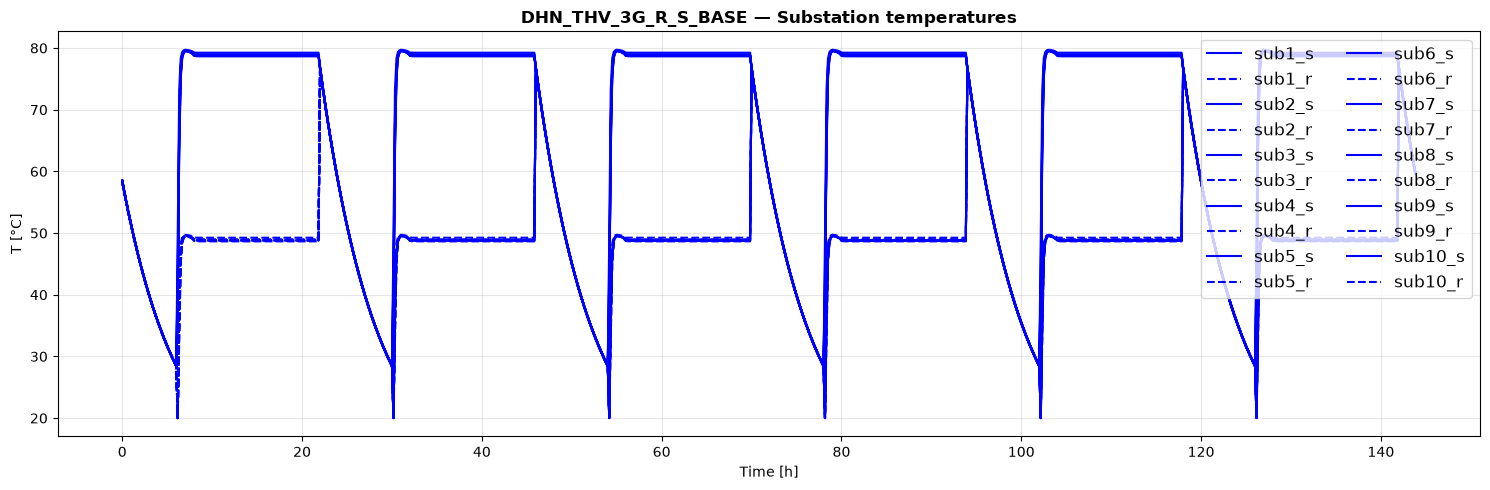

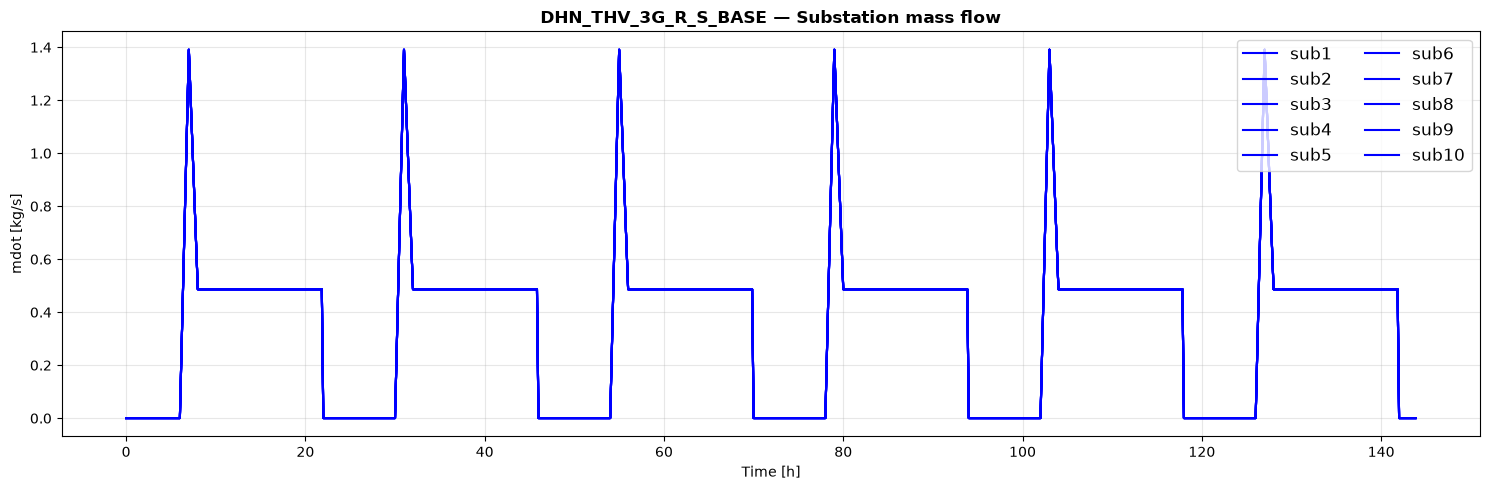

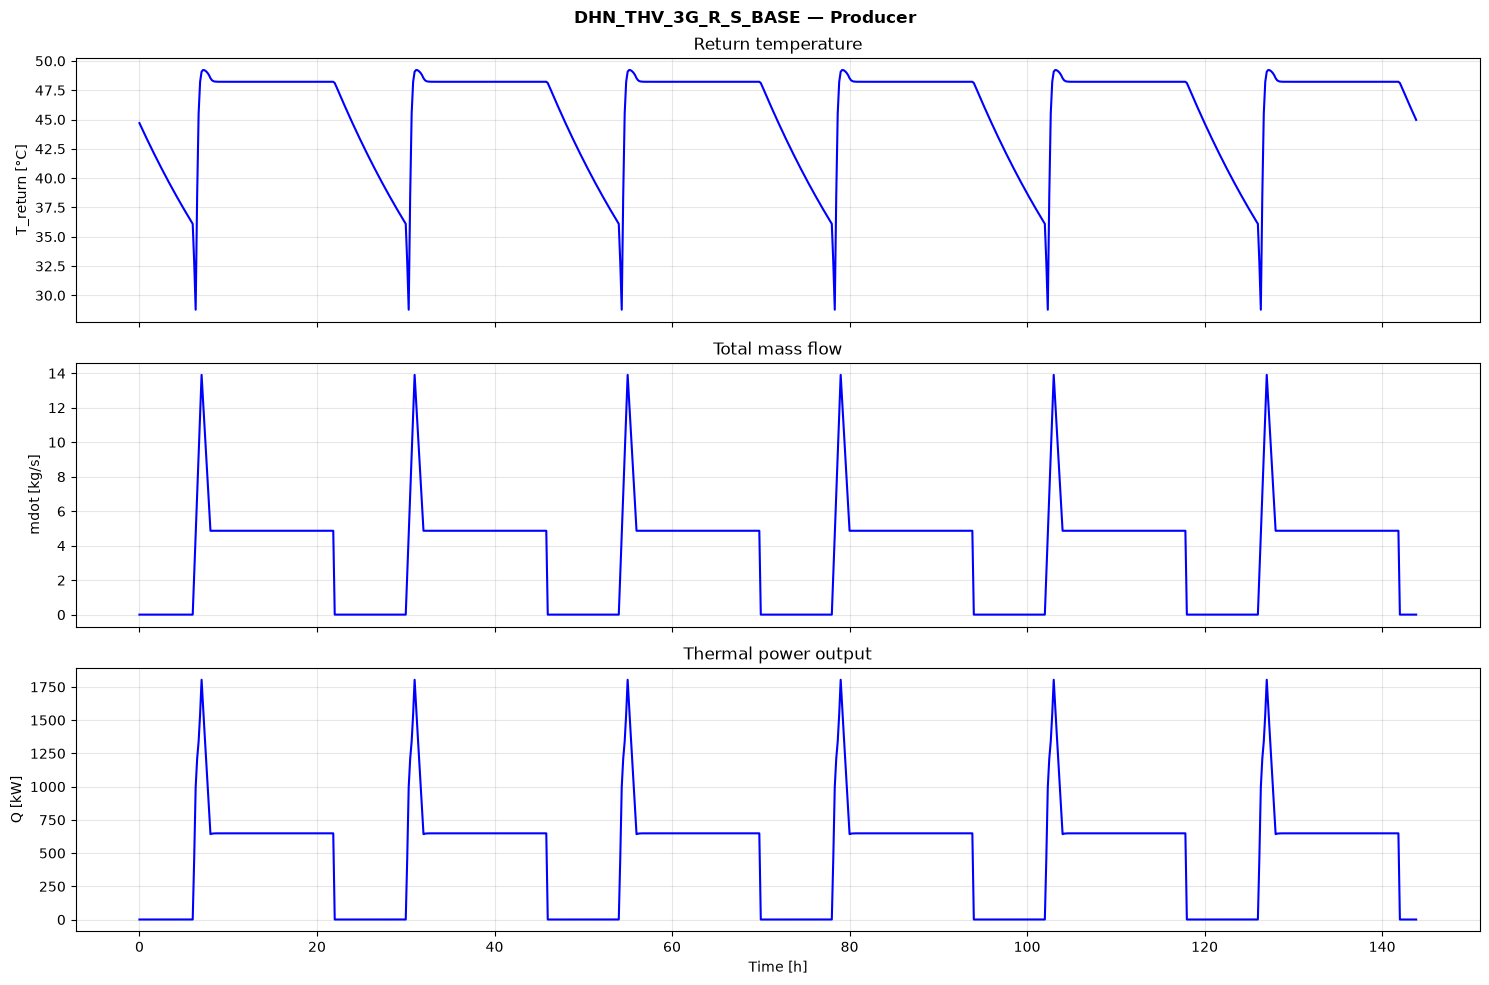

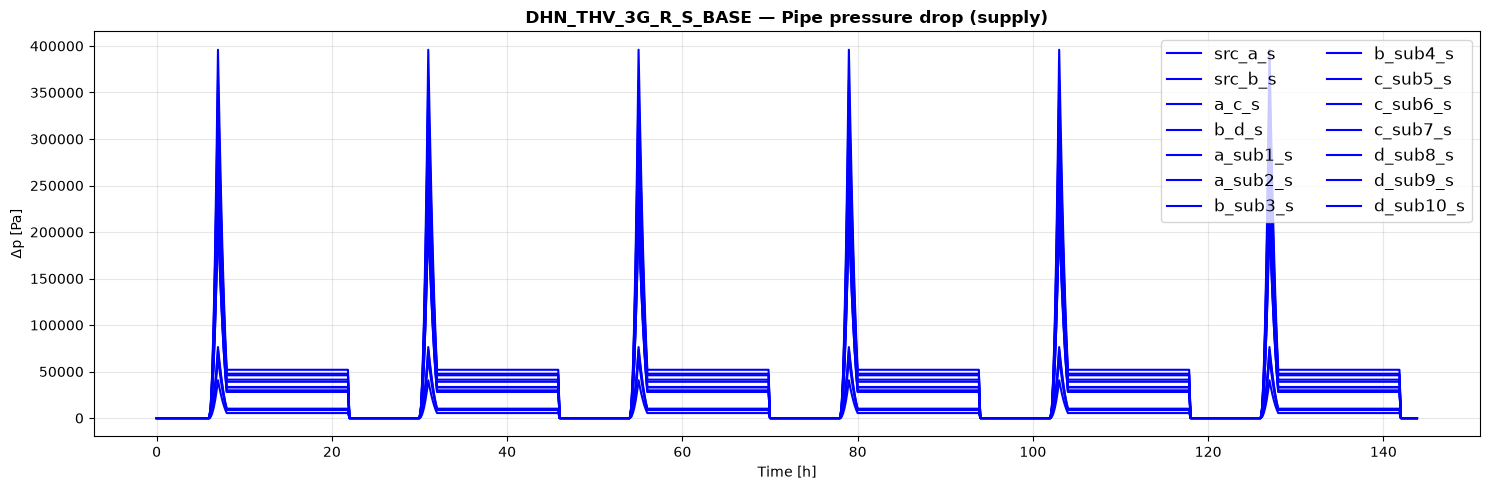

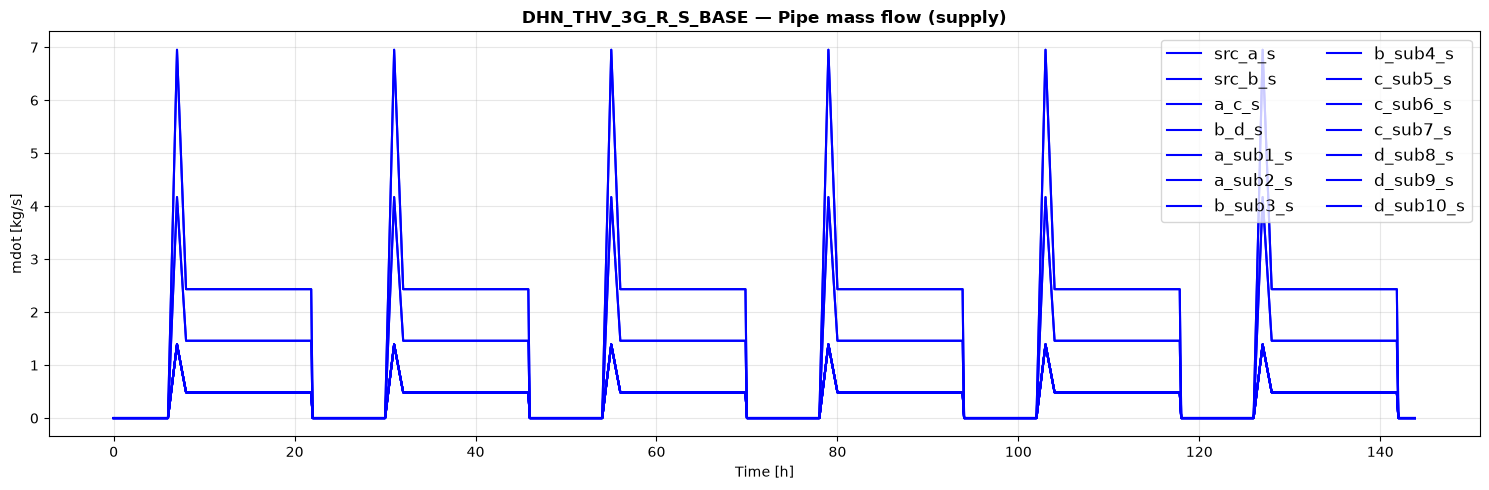

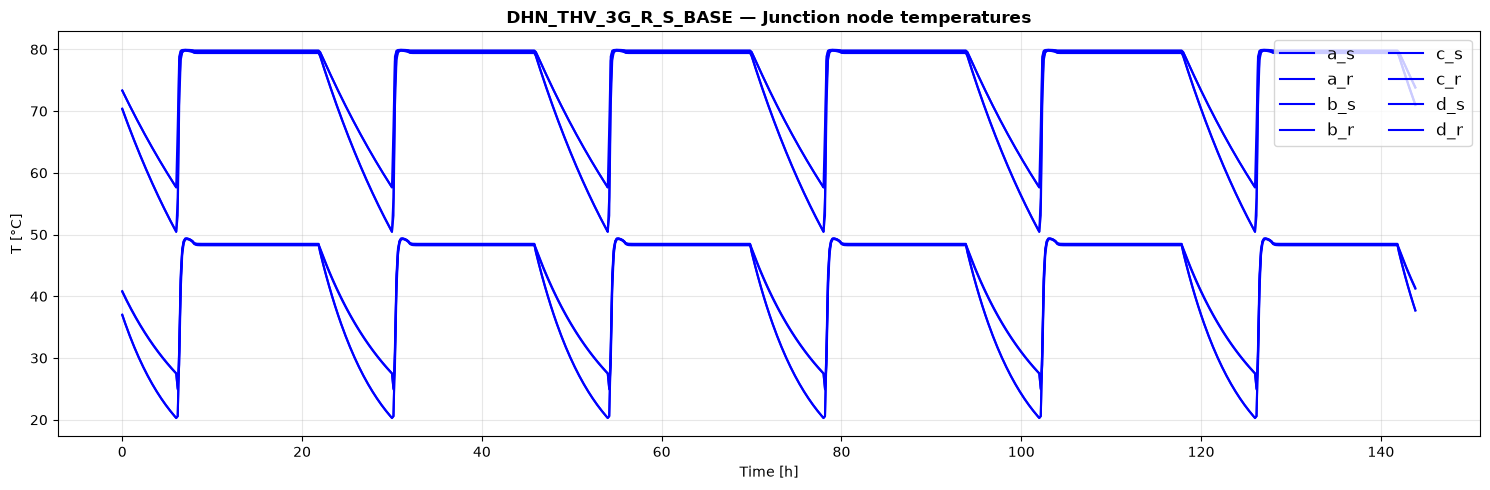

In [63]:
# ---------------------------------------------------------------------------
# Plot results
# ---------------------------------------------------------------------------
SKIP = 144
time_plot = np.arange(NUM_SIM_STEPS - SKIP) * STEPSIZE / 3600  # [h]

# ── SUBSTATIONS: temperatures ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
for n in substation_names:
    ax.plot(time_plot, T_sub_s[f"{n}_s"].iloc[SKIP:].values, color="blue", linestyle="-",  label=f"{n}_s")
    ax.plot(time_plot, T_sub_r[f"{n}_r"].iloc[SKIP:].values, color="blue", linestyle="--", label=f"{n}_r")
ax.set_xlabel("Time [h]")
ax.set_ylabel("T [°C]")
ax.set_title("DHN_THV_3G_R_S_BASE — Substation temperatures", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── SUBSTATIONS: mass flow ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
for n in substation_names:
    ax.plot(time_plot, mdot_sub[n].iloc[SKIP:].values, color="blue", linestyle="-", label=n)
ax.set_xlabel("Time [h]")
ax.set_ylabel("mdot [kg/s]")
ax.set_title("DHN_THV_3G_R_S_BASE — Substation mass flow", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── PRODUCER ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

axes[0].plot(time_plot, T_src_r.iloc[SKIP:].values, color="blue")
axes[0].set_ylabel("T_return [°C]")
axes[0].set_title("Return temperature")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_plot, mdot_src.iloc[SKIP:].values, color="blue")
axes[1].set_ylabel("mdot [kg/s]")
axes[1].set_title("Total mass flow")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_plot, Q_src_W.iloc[SKIP:].values / 1e3, color="blue")
axes[2].set_ylabel("Q [kW]")
axes[2].set_title("Thermal power output")
axes[2].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time [h]")
fig.suptitle("DHN_THV_3G_R_S_BASE — Producer", fontweight="bold")
plt.tight_layout()
plt.show()

# ── PIPES: pressure drop ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
for n in pipe_names:
    ax.plot(time_plot, dp_pipe_s[f"{n}_s"].iloc[SKIP:].values, color="blue", linestyle="-", label=f"{n}_s")
ax.set_xlabel("Time [h]")
ax.set_ylabel("Δp [Pa]")
ax.set_title("DHN_THV_3G_R_S_BASE — Pipe pressure drop (supply)", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── PIPES: mass flow ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 5))
for n in pipe_names:
    ax.plot(time_plot, mdot_pipe_s[f"{n}_s"].iloc[SKIP:].values, color="blue", linestyle="-", label=f"{n}_s")
ax.set_xlabel("Time [h]")
ax.set_ylabel("mdot [kg/s]")
ax.set_title("DHN_THV_3G_R_S_BASE — Pipe mass flow (supply)", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── JUNCTION NODES: temperatures ─────────────────────────────────────────────
substation_node_ids = (
    [f"{n}_s" for n in substation_names] +
    [f"{n}_r" for n in substation_names]
)
source_node_ids = [f"{source_name}_s", f"{source_name}_r"]
exclude_ids     = set(substation_node_ids + source_node_ids)
junction_cols   = [c for c in res["nodes"]["temperature"].columns if c not in exclude_ids]

fig, ax = plt.subplots(figsize=(15, 5))
for col in junction_cols:
    ax.plot(time_plot, res["nodes"]["temperature"][col].iloc[SKIP:].values,
            color="blue", linestyle="-", label=col)
ax.set_xlabel("Time [h]")
ax.set_ylabel("T [°C]")
ax.set_title("DHN_THV_3G_R_S_BASE — Junction node temperatures", fontweight="bold")
ax.legend(loc="upper right", fontsize=12, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()